# Notebook 14: Contact quality, sex, and the quality-adjusted sex association

Addresses **Reviewer 1 #8**: *"The reported sex-related associations may also be influenced by
differences in headset fit, electrode positioning, and recording quality. Please examine
whether the available signal-quality measures differ between male and female participants and
whether adjusting for these measures changes the observed associations."*

## What the exported data actually contains — read this first

The per-participant files carry **`CQ.<channel>`** columns: the *contact-quality* stream,
which reports electrode impedance. They do **not** carry the per-channel **EQ** score or the
session-level 0–100 score that Section 4.2 of the manuscript describes as the basis for
sample exclusion. Two consequences:

1. **This notebook tests contact quality, not EQ.** That is not a weakness for R1 #8 — the
   reviewer asks about electrode contact and headset fit, and CQ measures contact directly —
   but the response letter must name CQ rather than implying the EQ composite was analysed.
2. **The exclusion rule in Section 4.2 cannot be reproduced from these files.** No notebook
   in this project applies it: notebook 01 reads only the 70 power columns and `task_name`,
   with no quality filtering. Either the parent BRAINACTIV pipeline applied the rule before
   these CSVs were exported, in which case Section 4.2 should say so explicitly, or it was not
   applied to this dataset, in which case Section 4.2 overstates what was done. **Worth
   settling before answering R1 #8**, because this question invites the reviewer to look
   exactly here.

There is no head-circumference or headset-size variable in the metadata, so headset *fit* as
such cannot be tested; contact quality is the available proxy. Section 3.2 already concedes
the fit confound, and that concession should stand rather than being presented as resolved.

## Structure

| Part | Question |
|---|---|
| **A** | Build per-participant and per-task contact-quality summaries from the raw files, and report the observed CQ scale |
| **B** | Does contact quality differ between the sexes — overall, per channel, and specifically at the channels carrying Components 1 and 4? |
| **C** | Does adjusting for contact quality change the association? Per-component logistic adjustment, and the full omnibus screen on a CQ-residualised embedding |
| **D** | Does the association survive a stricter quality filter? Rebuild the feature matrix excluding low-CQ samples, refit, and re-test |

Part D is the strongest form of the answer: rather than statistically adjusting for quality,
it discards the samples that fail a stricter criterion and asks whether the result holds.

## Inputs

Raw: `data/eeg_features/BA*/2_emotiv_fft_values.csv`, `data/stimuli.csv`
Outputs of earlier notebooks: `outputs/feature_matrix.csv`, `outputs/feature_matrix_raw.csv`,
`outputs/metadata.csv`, `outputs/nmf_H.csv`, `outputs/posthoc_per_component.csv`,
`outputs/omnibus_results.csv`

## Outputs

CSVs: `nb14_cq_participant.csv`, `nb14_cq_by_sex.csv`, `nb14_cq_by_category.csv`,
`nb14_adjusted_percomponent.csv`, `nb14_residualised_omnibus.csv`, `nb14_cqfilter_refit.csv`

Figures: `nb14_fig_cq_by_sex.png`, `nb14_fig_adjustment.png` — 300 dpi

Summary: `nb14_summary.txt`

## Setup

In [1]:
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import NMF, PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path(".").resolve().parent
DATA_DIR = PROJECT_ROOT / "data"
EEG_DIR = DATA_DIR / "eeg_features"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

RAW_FILENAME = "2_emotiv_fft_values.csv"

CHANNELS = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1",
            "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"]
FREQ_BANDS = ["Theta", "Alpha", "BetaL", "BetaH", "Gamma"]
POW_COLS = [f"POW.{ch}.{band}" for ch in CHANNELS for band in FREQ_BANDS]
CQ_COLS = [f"CQ.{ch}" for ch in CHANNELS]

# --- NMF settings: identical to Notebook 02 ---
MAX_ITER = 500
TOL = 1e-4
RANDOM_SEED_BASE = 42
N_INIT_FULL = 50
PUBLISHED_K = 5

# --- Winsorisation percentiles: must match Notebook 01 ---
LOWER_PCT, UPPER_PCT = 2.5, 97.5

# --- Omnibus settings: identical to Notebook 04 ---
N_PERMUTATIONS = 5000
FDR_ALPHA = 0.05
PERM_SEED = 42

# --- Part C: how many principal components of the channel CQ profile to adjust for ---
N_CQ_PCS = 3

# --- Part D: a sample is kept if EVERY channel's CQ is at or above the level ---
# The observed CQ scale is printed in Part A; adjust these if it is not 0-4.
CQ_FILTER_LEVELS = [2, 4]
MIN_SAMPLES_PER_CATEGORY = 10   # a (participant, category) cell below this becomes missing

# --- Channels carrying the two sex-associated components (from Section 2.1) ---
COMP1_CHANNELS = ["AF3", "AF4", "F7", "F3", "FC5"]
COMP4_CHANNELS = ["F4", "FC6", "O2", "F3", "AF4"]

SEX_COL = "Gender"

print(f"Raw file per participant: {RAW_FILENAME}")
print(f"Contact-quality columns:  {len(CQ_COLS)}")
print(f"CQ filter levels for Part D: {CQ_FILTER_LEVELS}")
print()
print("Expected runtime: Part A reads all 86 raw files, roughly 2-6 min. Part C and Part D")
print("each run the 17-variable permutation screen, roughly 5-15 min apiece.")

Raw file per participant: 2_emotiv_fft_values.csv
Contact-quality columns:  14
CQ filter levels for Part D: [2, 4]

Expected runtime: Part A reads all 86 raw files, roughly 2-6 min. Part C and Part D
each run the 17-variable permutation screen, roughly 5-15 min apiece.


## Load earlier outputs

In [2]:
feature_matrix = pd.read_csv(OUTPUT_DIR / "feature_matrix.csv", index_col="participant_id")
feature_matrix_raw = pd.read_csv(OUTPUT_DIR / "feature_matrix_raw.csv", index_col="participant_id")
feature_matrix_raw = feature_matrix_raw.loc[feature_matrix.index, feature_matrix.columns]
metadata = (pd.read_csv(OUTPUT_DIR / "metadata.csv")
            .set_index("participant_id")
            .reindex(feature_matrix.index))
H_ref = pd.read_csv(OUTPUT_DIR / "nmf_H.csv", index_col=0)
W_ref = pd.read_csv(OUTPUT_DIR / "nmf_W.csv", index_col="participant_id")

COMP_LABELS = list(H_ref.index)
H_REF_ARR = H_ref.values
PIDS = feature_matrix.index.to_numpy()
N = len(PIDS)

raw_sex = metadata[SEX_COL].astype(str).str.strip().str.upper().str[0]
if not set(raw_sex.dropna().unique()) <= {"M", "F"}:
    raise ValueError(f"Could not read {SEX_COL!r} as M/F: "
                     f"{sorted(metadata[SEX_COL].dropna().unique())}")
SEX = raw_sex.values

PUBLISHED_EFFECTS = pd.read_csv(OUTPUT_DIR / "posthoc_per_component.csv")
PUBLISHED_EFFECTS = (PUBLISHED_EFFECTS[PUBLISHED_EFFECTS["variable"] == SEX_COL]
                     .set_index("component"))

print(f"{N} participants ({(SEX == 'M').sum()} male, {(SEX == 'F').sum()} female)")
print(f"Components: {COMP_LABELS}")

86 participants (44 male, 42 female)
Components: ['comp_1', 'comp_2', 'comp_3', 'comp_4', 'comp_5']


## Shared helper functions

Reproduced from notebooks 01, 02, 04 and 05 so the statistics stay identical.

In [3]:
def preprocess_array(raw, fit_rows=None, lower_pct=LOWER_PCT, upper_pct=UPPER_PCT):
    """Notebook 01 transform: log1p -> winsorise -> min-max to [0, 1]."""
    logged = np.log1p(np.asarray(raw, dtype=float))
    fit = logged if fit_rows is None else logged[fit_rows]
    lo = np.percentile(fit, lower_pct, axis=0)
    hi = np.percentile(fit, upper_pct, axis=0)
    wins = np.clip(logged, lo, hi)
    wins_fit = wins if fit_rows is None else wins[fit_rows]
    fmin, fmax = wins_fit.min(axis=0), wins_fit.max(axis=0)
    span = fmax - fmin
    span[span == 0] = 1.0
    return np.clip((wins - fmin) / span, 0.0, 1.0)


def cosine_similarity_matrix(A, B):
    """Pairwise cosine similarity between rows of A and rows of B."""
    A_norm = A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-12)
    B_norm = B / (np.linalg.norm(B, axis=1, keepdims=True) + 1e-12)
    return A_norm @ B_norm.T


def match_to_reference(H_new, H_ref_arr=None):
    """Hungarian-match rows of H_new to the reference components."""
    if H_ref_arr is None:
        H_ref_arr = H_REF_ARR
    sim = cosine_similarity_matrix(H_ref_arr, H_new)
    row, col = linear_sum_assignment(-sim)
    cos = np.full(H_ref_arr.shape[0], np.nan)
    idx = np.full(H_ref_arr.shape[0], -1, dtype=int)
    cos[row] = sim[row, col]
    idx[row] = col
    return cos, idx


def fit_nmf_best(X, k, n_init, seed_base):
    """Fit NMF n_init times and return the lowest-error solution, as in Notebook 02."""
    best = None
    for i in range(n_init):
        model = NMF(n_components=k, init="random", random_state=seed_base + i,
                    max_iter=MAX_ITER, tol=TOL, beta_loss="frobenius", solver="cd")
        W = model.fit_transform(X)
        if best is None or model.reconstruction_err_ < best[2]:
            best = (W, model.components_, model.reconstruction_err_)
    return best


def rb_female_higher(values, sex_arr):
    """Mann-Whitney rank-biserial and p; positive means higher in female participants."""
    values = np.asarray(values, dtype=float)
    ok = ~np.isnan(values)
    values, sex_arr = values[ok], np.asarray(sex_arr)[ok]
    f = values[sex_arr == "F"]
    m = values[sex_arr == "M"]
    if len(f) < 3 or len(m) < 3:
        return np.nan, np.nan
    if np.allclose(values, values[0]):
        return 0.0, 1.0
    u, p = stats.mannwhitneyu(m, f, alternative="two-sided")
    return float(1 - (2 * u) / (len(m) * len(f))), float(p)


def make_logreg():
    """LogisticRegression, tolerating the removal of multi_class in newer scikit-learn."""
    try:
        return LogisticRegression(max_iter=2000, multi_class="auto", solver="lbfgs")
    except TypeError:
        return LogisticRegression(max_iter=2000, solver="lbfgs")


def log_likelihood_logistic(model, X, y):
    """Log-likelihood of a fitted logistic model."""
    proba = np.clip(model.predict_proba(X), 1e-12, 1 - 1e-12)
    if proba.shape[1] == 2:
        return np.sum(y * np.log(proba[:, 1]) + (1 - y) * np.log(proba[:, 0]))
    ll = 0.0
    for cls_idx, cls in enumerate(model.classes_):
        ll += np.sum(np.log(proba[y == cls, cls_idx]))
    return ll


def compute_statistic_classification(X, y):
    """McFadden pseudo-R-squared."""
    if len(np.unique(y)) < 2:
        return np.nan
    try:
        full = make_logreg().fit(X, y)
        ll_full = log_likelihood_logistic(full, X, y)
    except Exception:
        return np.nan
    _, counts = np.unique(y, return_counts=True)
    priors = counts / counts.sum()
    ll_null = sum(c * np.log(p) for c, p in zip(counts, priors))
    if ll_null == 0:
        return np.nan
    return 1 - (ll_full / ll_null)


def compute_statistic(X, y, vtype):
    """Dispatch to the statistic matching the variable's measurement scale."""
    if vtype == "continuous":
        return LinearRegression().fit(X, y).score(X, y)
    if vtype in ("binary", "multi"):
        return compute_statistic_classification(X, y)
    raise ValueError(f"Unknown vtype: {vtype}")


VAR_TYPES = {
    "Age":                               "continuous",
    "Gender":                            "binary",
    "Residential Area (Urban/Rural)":    "binary",
    "From City":                         "binary",
    "Single/NotSingle":                  "binary",
    "Education":                         "multi",
    "Field of Study":                    "multi",
    "Occupation":                        "multi",
    "# of LanguagesSpeak":               "continuous",
    "UsedToDoSport":                     "binary",
    "NowDoingSports_aWeek":              "continuous",
    "PlayingAnInstrument":               "binary",
    "History of Neurological Disorders": "binary",
    "Medication Usage":                  "binary",
    "Average Sleep Hours per Night":     "continuous",
    "Smoking (0,1,2,3)":                 "continuous",
    "Alchocol (0,1,2,3)":                "continuous",
}
VAR_TYPES = {v: t for v, t in VAR_TYPES.items() if v in metadata.columns}


def omnibus_screen(W_mat, n_perm, seed, keep_rows=None, verbose_var=None):
    """Notebook 04's omnibus permutation screen, applied to an arbitrary embedding.

    keep_rows optionally restricts the screen to a subset of participants, for use when a
    quality filter has removed some.
    """
    rng = np.random.default_rng(seed)
    meta = metadata if keep_rows is None else metadata.iloc[keep_rows]
    W_std = StandardScaler().fit_transform(W_mat)
    rows = []
    for var, vtype in VAR_TYPES.items():
        sub = pd.DataFrame({"y": meta[var].values})
        sub["idx"] = np.arange(len(sub))
        sub = sub.dropna()
        if len(sub) < 10:
            rows.append({"variable": var, "type": vtype, "n": len(sub),
                         "observed_stat": np.nan, "p_perm": np.nan, "note": "insufficient n"})
            continue
        X_use = W_std[sub["idx"].values]
        y_raw = sub["y"].values
        if vtype != "continuous":
            y_use, _ = pd.factorize(y_raw)
        else:
            y_num = pd.to_numeric(y_raw, errors="coerce")
            valid = ~pd.isna(y_num)
            if valid.sum() < 10:
                rows.append({"variable": var, "type": vtype, "n": int(valid.sum()),
                             "observed_stat": np.nan, "p_perm": np.nan,
                             "note": "insufficient numeric data"})
                continue
            X_use = X_use[valid]
            y_use = np.asarray(y_num[valid], dtype=float)
        obs = compute_statistic(X_use, y_use, vtype)
        if np.isnan(obs):
            rows.append({"variable": var, "type": vtype, "n": len(y_use),
                         "observed_stat": np.nan, "p_perm": np.nan, "note": "statistic failed"})
            continue
        null = np.zeros(n_perm)
        y_perm = np.array(y_use, copy=True)
        for i in range(n_perm):
            rng.shuffle(y_perm)
            null[i] = compute_statistic(X_use, y_perm, vtype)
        rows.append({"variable": var, "type": vtype, "n": len(y_use), "observed_stat": obs,
                     "null_mean": float(np.mean(null)),
                     "null_95pct": float(np.percentile(null, 95)),
                     "p_perm": (np.sum(null >= obs) + 1) / (n_perm + 1), "note": ""})
        if verbose_var and var == verbose_var:
            print(f"    {var}: stat={obs:.4f}, p_perm={rows[-1]['p_perm']:.4f}")
    out = pd.DataFrame(rows)
    ok = out["p_perm"].notna()
    out["p_fdr"] = np.nan
    out["significant_fdr"] = False
    if ok.any():
        reject, p_fdr, _, _ = multipletests(out.loc[ok, "p_perm"].values,
                                            alpha=FDR_ALPHA, method="fdr_bh")
        out.loc[ok, "p_fdr"] = p_fdr
        out.loc[ok, "significant_fdr"] = reject
    return out.sort_values("p_perm")


print(f"{len(VAR_TYPES)} metadata variables available for the omnibus screen")

17 metadata variables available for the omnibus screen


## Part A — Build contact-quality summaries from the raw files

One pass over the 86 raw files computes, per participant:

- the median and mean CQ at each of the 14 channels;
- the fraction of time-window samples in which *every* channel met each filter level;
- a session-level proxy built the way Section 4.2 describes the device's own score — the mean
  of the three lowest channel medians — so that something comparable to the described metric
  is available even though the device's score itself was not exported;
- the per-category power medians under each CQ filter level, for Part D.

Computing the filtered medians in the same pass avoids reading every raw file twice.

In [4]:
stimuli_df = pd.read_csv(DATA_DIR / "stimuli.csv")


def to_cat_key(lobe_str):
    """Sanitise a lobe label into a column prefix, as in Notebook 01."""
    return lobe_str.strip().lower().replace("-", "_").replace(" ", "_")


stimuli_df["category"] = stimuli_df["primary_lobe_targeted"].map(to_cat_key)
TASK_TO_CATEGORY = dict(zip(stimuli_df["original_stimuli_name"], stimuli_df["category"]))
CATEGORIES = sorted(stimuli_df["category"].unique())
print(f"{len(TASK_TO_CATEGORY)} tasks across {len(CATEGORIES)} categories: {CATEGORIES}")


def ba_sort_key(p):
    """Sort BA folders numerically, as in Notebook 01."""
    m = re.match(r"BA(\d+)", p.name)
    return int(m.group(1)) if m else 99999


participant_folders = sorted(
    [p for p in EEG_DIR.iterdir() if p.is_dir() and re.match(r"BA\d+", p.name)],
    key=ba_sort_key,
)
participant_folders = [p for p in participant_folders if p.name in set(PIDS)]
print(f"{len(participant_folders)} participant folders matching the analytic sample")

37 tasks across 5 categories: ['frontal', 'frontal_central', 'occipital', 'parietal', 'temporal']
86 participant folders matching the analytic sample


In [5]:
cq_rows = []
cq_task_rows = []
filtered_medians = {lvl: {} for lvl in CQ_FILTER_LEVELS}
retention_rows = []
observed_cq_values = set()

t0 = time.time()
for n_done, folder in enumerate(participant_folders, start=1):
    pid = folder.name
    df = pd.read_csv(folder / RAW_FILENAME)
    missing = [c for c in POW_COLS + CQ_COLS + ["task_name"] if c not in df.columns]
    if missing:
        raise ValueError(f"{pid}: missing columns {missing[:5]}")
    df = df.copy()
    df["category"] = df["task_name"].map(TASK_TO_CATEGORY)
    df = df[df["category"].notna()]
    cq = df[CQ_COLS]
    observed_cq_values.update(pd.unique(cq.values.ravel()))

    # Per-participant CQ summary
    row = {"participant_id": pid, "n_samples": len(df)}
    for ch in CHANNELS:
        row[f"median_CQ_{ch}"] = float(cq[f"CQ.{ch}"].median())
        row[f"mean_CQ_{ch}"] = float(cq[f"CQ.{ch}"].mean())
    chan_medians = np.array([row[f"median_CQ_{ch}"] for ch in CHANNELS], dtype=float)
    row["mean_CQ_all"] = float(cq.values.mean())
    row["min_channel_median"] = float(np.min(chan_medians))
    row["session_proxy_3lowest"] = float(np.sort(chan_medians)[:3].mean())
    row["mean_CQ_comp1_channels"] = float(np.mean([row[f"mean_CQ_{ch}"] for ch in COMP1_CHANNELS]))
    row["mean_CQ_comp4_channels"] = float(np.mean([row[f"mean_CQ_{ch}"] for ch in COMP4_CHANNELS]))
    for lvl in CQ_FILTER_LEVELS:
        keep = (cq >= lvl).all(axis=1)
        row[f"frac_samples_all_ge_{lvl}"] = float(keep.mean())
    cq_rows.append(row)

    # Per-task CQ, for the task-category check
    for (task, cat), sub in df.groupby(["task_name", "category"]):
        cq_task_rows.append({"participant_id": pid, "task": task, "category": cat,
                             "n_samples": len(sub),
                             "mean_CQ_all": float(sub[CQ_COLS].values.mean())})

    # Filtered category medians, for Part D
    for lvl in CQ_FILTER_LEVELS:
        keep = (cq >= lvl).all(axis=1)
        kept = df[keep.values]
        n_kept_total = int(len(kept))
        if len(kept):
            agg = kept.groupby("category")[POW_COLS].median()
            counts = kept.groupby("category").size()
            agg = agg[counts >= MIN_SAMPLES_PER_CATEGORY]
        else:
            agg = pd.DataFrame(columns=POW_COLS)
        flat = agg.stack()
        flat.index = [f"{cat}__{feat}" for cat, feat in flat.index]
        filtered_medians[lvl][pid] = flat
        retention_rows.append({"participant_id": pid, "level": lvl,
                               "n_samples_total": len(df), "n_samples_kept": n_kept_total,
                               "frac_kept": n_kept_total / max(len(df), 1),
                               "n_categories_kept": int(agg.shape[0])})
    if n_done % 20 == 0:
        print(f"  {n_done}/{len(participant_folders)} participants ({time.time() - t0:.0f}s)")

cq_df = pd.DataFrame(cq_rows).set_index("participant_id").reindex(PIDS)
cq_task_df = pd.DataFrame(cq_task_rows)
retention_df = pd.DataFrame(retention_rows)
cq_df.to_csv(OUTPUT_DIR / "nb14_cq_participant.csv")
print()
print(f"CQ summary built for {len(cq_df)} participants in {time.time() - t0:.0f}s")

  20/86 participants (8s)
  40/86 participants (13s)
  60/86 participants (17s)
  80/86 participants (24s)

CQ summary built for 86 participants in 26s


In [6]:
vals = sorted(float(v) for v in observed_cq_values if not pd.isna(v))
vals = [int(v) if float(v).is_integer() else round(v, 3) for v in vals]
print(f"Observed CQ values across the whole dataset: {vals}")
print()
if not set(vals) <= set(range(5)):
    print("NOTE: the CQ scale is not the expected 0-4. Check CQ_FILTER_LEVELS before")
    print("reading Part D, since the filter levels assume that scale.")
print("Distribution of per-participant mean CQ:")
print(cq_df["mean_CQ_all"].describe().round(3).to_string())
print()
print("Sample retention under each filter level:")
print(retention_df.groupby("level")[["frac_kept", "n_categories_kept"]]
      .agg(["mean", "min"]).round(3).to_string())

CQ_VARIES = cq_df["mean_CQ_all"].std() > 1e-9
if not CQ_VARIES:
    print()
    print("Per-participant mean CQ has no variance: contact quality is identical across")
    print("participants and therefore cannot confound the sex association. Parts B and C")
    print("will report this rather than fitting degenerate models.")

Observed CQ values across the whole dataset: [0, 1, 2, 4]

Distribution of per-participant mean CQ:
count    86.000
mean      3.980
std       0.062
min       3.554
25%       3.999
50%       4.000
75%       4.000
max       4.000

Sample retention under each filter level:
      frac_kept        n_categories_kept    
           mean    min              mean min
level                                       
2         0.964  0.423             4.953   3
4         0.932  0.237             4.919   2


## Part B — Does contact quality differ between the sexes?

Per-channel Mann–Whitney tests with Benjamini–Hochberg correction across the 14 channels,
plus the aggregate measures and the two component-specific channel sets. The last of these is
the one that matters most: a sex difference in contact quality concentrated at the anterior
frontal channels carrying Component 1 would be the mechanism by which R1 #8's concern becomes
real.

In [7]:
cq_test_rows = []
for ch in CHANNELS:
    r, p = rb_female_higher(cq_df[f"mean_CQ_{ch}"].values, SEX)
    cq_test_rows.append({"measure": f"mean_CQ_{ch}", "scope": "channel", "channel": ch,
                         "rank_biserial": r, "p_raw": p})
cq_tests = pd.DataFrame(cq_test_rows)
ok = cq_tests["p_raw"].notna()
cq_tests["p_fdr"] = np.nan
cq_tests["significant_fdr"] = False
if ok.any():
    reject, p_fdr, _, _ = multipletests(cq_tests.loc[ok, "p_raw"].values,
                                        alpha=FDR_ALPHA, method="fdr_bh")
    cq_tests.loc[ok, "p_fdr"] = p_fdr
    cq_tests.loc[ok, "significant_fdr"] = reject

aggregate_rows = []
for measure in ["mean_CQ_all", "min_channel_median", "session_proxy_3lowest",
                "mean_CQ_comp1_channels", "mean_CQ_comp4_channels"] + \
               [f"frac_samples_all_ge_{lvl}" for lvl in CQ_FILTER_LEVELS]:
    r, p = rb_female_higher(cq_df[measure].values, SEX)
    aggregate_rows.append({"measure": measure, "scope": "aggregate", "channel": "",
                           "rank_biserial": r, "p_raw": p, "p_fdr": np.nan,
                           "significant_fdr": False})

cq_by_sex = pd.concat([cq_tests, pd.DataFrame(aggregate_rows)], ignore_index=True)
cq_by_sex.to_csv(OUTPUT_DIR / "nb14_cq_by_sex.csv", index=False)

print("Per-channel contact quality by sex (positive = higher CQ in female participants;")
print("FDR corrected across the 14 channels):")
print(cq_tests[["channel", "rank_biserial", "p_raw", "p_fdr", "significant_fdr"]]
      .round(4).to_string(index=False))
print()
print("Aggregate measures (reported with uncorrected p-values, as a small fixed set):")
print(pd.DataFrame(aggregate_rows)[["measure", "rank_biserial", "p_raw"]].round(4).to_string(index=False))
print()
n_sig = int(cq_tests["significant_fdr"].sum())
if n_sig:
    chans = list(cq_tests[cq_tests["significant_fdr"]]["channel"])
    print(f"=> {n_sig} channel(s) show a sex difference in contact quality: {chans}")
    overlap1 = sorted(set(chans) & set(COMP1_CHANNELS))
    overlap4 = sorted(set(chans) & set(COMP4_CHANNELS))
    print(f"   overlap with Component 1 channels: {overlap1 if overlap1 else 'none'}")
    print(f"   overlap with Component 4 channels: {overlap4 if overlap4 else 'none'}")
    if overlap1 or overlap4:
        print("   This is the case R1 #8 is worried about. Part C and Part D decide whether")
        print("   it accounts for the association or merely coexists with it.")
else:
    print("=> No channel shows a sex difference in contact quality after correction.")

Per-channel contact quality by sex (positive = higher CQ in female participants;
FDR corrected across the 14 channels):
channel  rank_biserial  p_raw  p_fdr  significant_fdr
    AF3        -0.0541 0.4423 0.6309            False
     F7        -0.0498 0.3734 0.6309            False
     F3        -0.0595 0.3976 0.6309            False
    FC5        -0.0335 0.6199 0.6676            False
     T7        -0.1234 0.0649 0.2701            False
     P7        -0.0049 0.9505 0.9505            False
     O1        -0.0422 0.5502 0.6419            False
     O2        -0.1645 0.0357 0.2701            False
     P8        -0.1429 0.0772 0.2701            False
     T8        -0.0660 0.4017 0.6309            False
    FC6        -0.0503 0.5095 0.6419            False
     F4        -0.1212 0.0698 0.2701            False
     F8        -0.0482 0.4506 0.6309            False
    AF4        -0.0823 0.2610 0.6309            False

Aggregate measures (reported with uncorrected p-values, as a small fi

In [8]:
cat_summary = (cq_task_df.merge(
    pd.DataFrame({"participant_id": PIDS, "sex": SEX}), on="participant_id")
    .groupby(["category", "sex"])["mean_CQ_all"].mean().unstack())
cat_summary.to_csv(OUTPUT_DIR / "nb14_cq_by_category.csv")
print("Mean contact quality by task category and sex:")
print(cat_summary.round(3).to_string())

Mean contact quality by task category and sex:
sex                  F      M
category                     
frontal          3.988  3.986
frontal_central  3.990  3.946
occipital        3.991  3.987
parietal         3.976  3.982
temporal         3.974  3.986


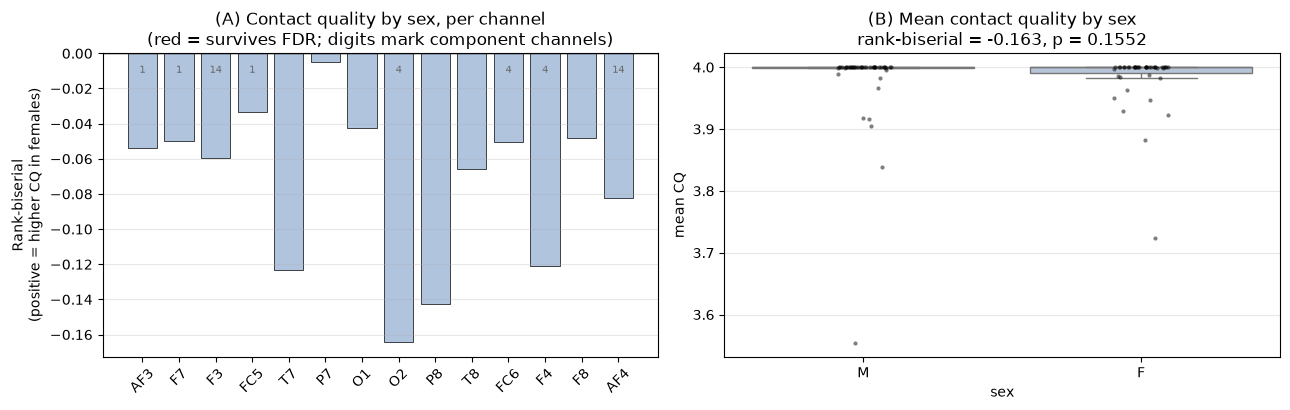

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

ax = axes[0]
colours = ["firebrick" if s else "lightsteelblue" for s in cq_tests["significant_fdr"]]
ax.bar(cq_tests["channel"], cq_tests["rank_biserial"], color=colours, edgecolor="black",
       linewidth=0.5)
ax.axhline(0, color="black", linewidth=1)
for i, ch in enumerate(cq_tests["channel"]):
    if ch in COMP1_CHANNELS or ch in COMP4_CHANNELS:
        marks = ("1" if ch in COMP1_CHANNELS else "") + ("4" if ch in COMP4_CHANNELS else "")
        ax.annotate(marks, (i, 0), textcoords="offset points", xytext=(0, -14),
                    ha="center", fontsize=7, color="dimgrey")
ax.set_ylabel("Rank-biserial\n(positive = higher CQ in females)")
ax.set_title("(A) Contact quality by sex, per channel\n(red = survives FDR; digits mark component channels)")
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.3, axis="y")

ax = axes[1]
plot_df = pd.DataFrame({"mean CQ": cq_df["mean_CQ_all"].values, "sex": SEX})
sns.boxplot(data=plot_df, x="sex", y="mean CQ", ax=ax, showfliers=False, color="lightsteelblue")
sns.stripplot(data=plot_df, x="sex", y="mean CQ", ax=ax, color="black", alpha=0.5, size=3)
r_all, p_all = rb_female_higher(cq_df["mean_CQ_all"].values, SEX)
ax.set_title(f"(B) Mean contact quality by sex\nrank-biserial = {r_all:+.3f}, p = {p_all:.4f}")
ax.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nb14_fig_cq_by_sex.png", dpi=300, bbox_inches="tight")
plt.show()

## Part C — Does adjusting for contact quality change the association?

Two adjustments, both using the same covariate set: overall mean CQ plus the first
`N_CQ_PCS` principal components of the 14 channel-wise CQ profile, so that both the level and
the topography of contact quality are controlled.

1. **Per component** — logistic regression of sex on the component loading plus the
   covariates, compared by likelihood-ratio test against a covariates-only model. This gives
   an adjusted p-value for each component alongside the unadjusted Mann–Whitney result.
2. **Whole embedding** — each component is residualised on the covariates, and the full
   17-variable omnibus screen is re-run on the residualised embedding, so the headline
   statistic is directly comparable with the published 0.274.

In [10]:
if not CQ_VARIES:
    print("Contact quality does not vary across participants; adjustment is undefined.")
    adjusted_df = pd.DataFrame()
    resid_omnibus = pd.DataFrame()
else:
    chan_profile = cq_df[[f"mean_CQ_{ch}" for ch in CHANNELS]].values
    chan_profile_std = StandardScaler().fit_transform(chan_profile)
    n_pcs = min(N_CQ_PCS, chan_profile_std.shape[1])
    pca_cq = PCA(n_components=n_pcs, random_state=0).fit(chan_profile_std)
    cq_pcs = pca_cq.transform(chan_profile_std)
    COVARS = np.column_stack([cq_df["mean_CQ_all"].values, cq_pcs])
    COVARS = StandardScaler().fit_transform(COVARS)
    print(f"Covariates: overall mean CQ + {n_pcs} PCs of the channel CQ profile")
    print(f"PC variance explained: {np.round(pca_cq.explained_variance_ratio_, 3)} "
          f"(cumulative {pca_cq.explained_variance_ratio_.sum():.3f})")

    y_sex = (np.asarray(SEX) == "F").astype(int)
    rows = []
    for ci, lab in enumerate(COMP_LABELS):
        comp = W_ref[lab].values.reshape(-1, 1)
        comp_std = StandardScaler().fit_transform(comp)
        X_full = np.column_stack([comp_std, COVARS])
        X_null = COVARS
        try:
            m_full = make_logreg().fit(X_full, y_sex)
            m_null = make_logreg().fit(X_null, y_sex)
            ll_full = log_likelihood_logistic(m_full, X_full, y_sex)
            ll_null = log_likelihood_logistic(m_null, X_null, y_sex)
            lr = 2 * (ll_full - ll_null)
            p_adj = float(stats.chi2.sf(max(lr, 0.0), df=1))
            beta = float(m_full.coef_[0][0])
        except Exception as exc:
            lr, p_adj, beta = np.nan, np.nan, np.nan
            print(f"  {lab}: adjustment failed ({exc})")
        r_un, p_un = rb_female_higher(W_ref[lab].values, SEX)
        rows.append({"component": lab, "rank_biserial_unadjusted": r_un,
                     "p_unadjusted": p_un, "logistic_beta_adjusted": beta,
                     "LR_chi2": lr, "p_adjusted": p_adj,
                     "published_r": PUBLISHED_EFFECTS["effect_size"].get(lab, np.nan)})
    adjusted_df = pd.DataFrame(rows)
    okc = adjusted_df["p_adjusted"].notna()
    adjusted_df["p_adjusted_fdr"] = np.nan
    if okc.any():
        _, p_fdr_adj, _, _ = multipletests(adjusted_df.loc[okc, "p_adjusted"].values,
                                           alpha=FDR_ALPHA, method="fdr_bh")
        adjusted_df.loc[okc, "p_adjusted_fdr"] = p_fdr_adj
    adjusted_df.to_csv(OUTPUT_DIR / "nb14_adjusted_percomponent.csv", index=False)
    print()
    print("Per-component sex association before and after adjusting for contact quality:")
    print(adjusted_df.round(4).to_string(index=False))

Covariates: overall mean CQ + 3 PCs of the channel CQ profile
PC variance explained: [0.514 0.113 0.102] (cumulative 0.729)

Per-component sex association before and after adjusting for contact quality:
component  rank_biserial_unadjusted  p_unadjusted  logistic_beta_adjusted  LR_chi2  p_adjusted  published_r  p_adjusted_fdr
   comp_1                    0.5768        0.0000                  1.3094  23.5468      0.0000       0.5768          0.0000
   comp_2                    0.1331        0.2898                  0.2448   1.1958      0.2742       0.1331          0.4569
   comp_3                    0.0400        0.7523                  0.1260   0.3020      0.5826       0.0400          0.5826
   comp_4                   -0.3144        0.0122                 -0.5004   4.8821      0.0271      -0.3144          0.0678
   comp_5                   -0.0574        0.6498                 -0.1311   0.4051      0.5245      -0.0574          0.5826


In [11]:
if CQ_VARIES:
    resid = np.zeros_like(W_ref.values, dtype=float)
    for ci in range(W_ref.shape[1]):
        fit = LinearRegression().fit(COVARS, W_ref.values[:, ci])
        resid[:, ci] = W_ref.values[:, ci] - fit.predict(COVARS)
        print(f"  {COMP_LABELS[ci]}: R^2 of CQ covariates on the loading = "
              f"{fit.score(COVARS, W_ref.values[:, ci]):.4f}")
    print()
    print(f"Omnibus screen on the CQ-residualised embedding "
          f"({len(VAR_TYPES)} variables x {N_PERMUTATIONS} permutations)")
    t0 = time.time()
    resid_omnibus = omnibus_screen(resid, N_PERMUTATIONS, PERM_SEED, verbose_var=SEX_COL)
    resid_omnibus.to_csv(OUTPUT_DIR / "nb14_residualised_omnibus.csv", index=False)
    print(f"  done in {time.time() - t0:.0f}s")

    pub_omni = pd.read_csv(OUTPUT_DIR / "omnibus_results.csv")
    pub_sex = pub_omni[pub_omni["variable"] == SEX_COL].iloc[0]
    res_sex = resid_omnibus[resid_omnibus["variable"] == SEX_COL].iloc[0]
    print()
    print(f"Published:    stat={pub_sex['observed_stat']:.4f}, p_perm={pub_sex['p_perm']:.4f}, "
          f"p_fdr={pub_sex['p_fdr']:.4f}")
    print(f"CQ-adjusted:  stat={res_sex['observed_stat']:.4f}, p_perm={res_sex['p_perm']:.4f}, "
          f"p_fdr={res_sex['p_fdr']:.4f}")
    survivors = list(resid_omnibus[resid_omnibus["significant_fdr"]]["variable"])
    print(f"Variables surviving FDR after adjustment: {survivors if survivors else 'none'}")

  comp_1: R^2 of CQ covariates on the loading = 0.0286
  comp_2: R^2 of CQ covariates on the loading = 0.1003
  comp_3: R^2 of CQ covariates on the loading = 0.1209
  comp_4: R^2 of CQ covariates on the loading = 0.1192
  comp_5: R^2 of CQ covariates on the loading = 0.0397

Omnibus screen on the CQ-residualised embedding (17 variables x 5000 permutations)
    Gender: stat=0.2538, p_perm=0.0002
  done in 311s

Published:    stat=0.2742, p_perm=0.0002, p_fdr=0.0034
CQ-adjusted:  stat=0.2538, p_perm=0.0002, p_fdr=0.0034
Variables surviving FDR after adjustment: ['Gender']


## Part D — Refit after excluding low-contact-quality samples

The strongest form of the answer. Rather than adjusting statistically, the feature matrix is
rebuilt from the raw samples that pass each filter level, the pipeline is refit at k = 5, and
the sex association is re-tested. The components of each refit are matched to the published
solution so the comparison is like for like.

A `(participant, category)` cell with fewer than `MIN_SAMPLES_PER_CATEGORY` surviving samples
is treated as missing; a participant missing any category is dropped from that filter level,
and the number dropped is reported — at the strictest level this may become the binding
constraint rather than the sex association.

In [12]:
refit_rows = []
for lvl in CQ_FILTER_LEVELS:
    mat = pd.DataFrame(filtered_medians[lvl]).T
    mat.index.name = "participant_id"
    mat = mat.reindex(columns=feature_matrix.columns)
    complete = mat.dropna(axis=0, how="any")
    dropped = [p for p in PIDS if p not in complete.index]
    shown = ", ".join(dropped[:10]) + (f" ... +{len(dropped) - 10} more" if len(dropped) > 10 else "")
    print(f"=== CQ >= {lvl} on every channel ===")
    print(f"  participants retained: {len(complete)}/{N}"
          + (f" (dropped {len(dropped)}: {shown})" if dropped else ""))
    if len(complete) < 30:
        print("  too few participants retained for a meaningful refit; skipping this level")
        print()
        continue

    keep_pos = [int(np.where(PIDS == p)[0][0]) for p in complete.index]
    sex_lvl = SEX[keep_pos]
    X_lvl = preprocess_array(complete.values)
    W_lvl, H_lvl, err_lvl = fit_nmf_best(X_lvl, PUBLISHED_K, N_INIT_FULL, RANDOM_SEED_BASE)
    cos, idx = match_to_reference(H_lvl)
    print(f"  cosine to published components: {np.round(cos, 3)}")

    omni_lvl = omnibus_screen(W_lvl, N_PERMUTATIONS, PERM_SEED, keep_rows=keep_pos,
                              verbose_var=SEX_COL)
    sex_row = omni_lvl[omni_lvl["variable"] == SEX_COL].iloc[0]
    survivors = list(omni_lvl[omni_lvl["significant_fdr"]]["variable"])
    print(f"  omnibus sex: stat={sex_row['observed_stat']:.4f}, "
          f"p_perm={sex_row['p_perm']:.4f}, p_fdr={sex_row['p_fdr']:.4f}")
    print(f"  variables surviving FDR: {survivors if survivors else 'none'}")

    per_comp = []
    for ci, lab in enumerate(COMP_LABELS):
        r, p = rb_female_higher(W_lvl[:, idx[ci]], sex_lvl)
        per_comp.append({"component": lab, "rank_biserial": r, "p_raw": p})
    pc = pd.DataFrame(per_comp)
    okp = pc["p_raw"].notna()
    pc["p_fdr"] = np.nan
    if okp.any():
        _, pf, _, _ = multipletests(pc.loc[okp, "p_raw"].values, alpha=FDR_ALPHA, method="fdr_bh")
        pc.loc[okp, "p_fdr"] = pf
    print("  per-component sex effects (matched to published components):")
    print(pc.round(4).to_string(index=False))
    print()

    for ci, lab in enumerate(COMP_LABELS):
        refit_rows.append({
            "level": lvl, "n_participants": len(complete), "component": lab,
            "cosine_to_published": cos[ci],
            "rank_biserial": pc.loc[ci, "rank_biserial"], "p_raw": pc.loc[ci, "p_raw"],
            "p_fdr": pc.loc[ci, "p_fdr"],
            "published_r": PUBLISHED_EFFECTS["effect_size"].get(lab, np.nan),
            "omnibus_stat": sex_row["observed_stat"], "omnibus_p_perm": sex_row["p_perm"],
            "omnibus_p_fdr": sex_row["p_fdr"], "recon_error": err_lvl,
        })

refit_df = pd.DataFrame(refit_rows)
if len(refit_df):
    refit_df.to_csv(OUTPUT_DIR / "nb14_cqfilter_refit.csv", index=False)
    print(f"Saved {OUTPUT_DIR / 'nb14_cqfilter_refit.csv'}")

=== CQ >= 2 on every channel ===
  participants retained: 84/86 (dropped 2: BA35, BA51)
  cosine to published components: [0.995 0.969 0.965 0.987 0.996]
    Gender: stat=0.2577, p_perm=0.0002
  omnibus sex: stat=0.2577, p_perm=0.0002, p_fdr=0.0034
  variables surviving FDR: ['Gender']
  per-component sex effects (matched to published components):
component  rank_biserial  p_raw  p_fdr
   comp_1         0.5649 0.0000 0.0000
   comp_2         0.0437 0.7335 0.8019
   comp_3         0.1083 0.3939 0.6565
   comp_4        -0.3074 0.0154 0.0385
   comp_5        -0.0323 0.8019 0.8019

=== CQ >= 4 on every channel ===
  participants retained: 82/86 (dropped 4: BA13, BA35, BA44, BA51)
  cosine to published components: [0.996 0.985 0.97  0.996 0.993]
    Gender: stat=0.2813, p_perm=0.0002
  omnibus sex: stat=0.2813, p_perm=0.0002, p_fdr=0.0034
  variables surviving FDR: ['Gender']
  per-component sex effects (matched to published components):
component  rank_biserial  p_raw  p_fdr
   comp_1     

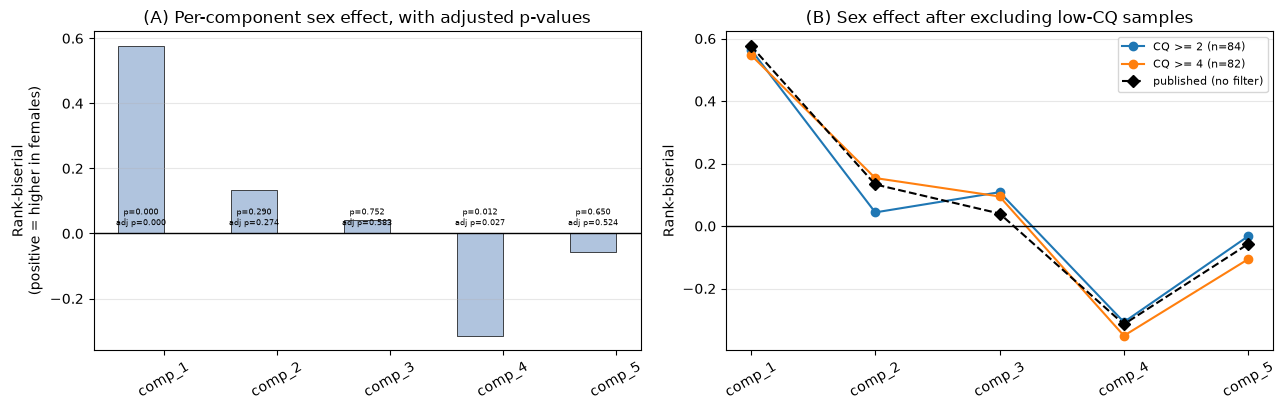

In [13]:
if len(refit_df) and CQ_VARIES and len(adjusted_df):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

    ax = axes[0]
    x = np.arange(len(COMP_LABELS))
    ax.bar(x - 0.2, adjusted_df["rank_biserial_unadjusted"], width=0.4,
           label="unadjusted", color="lightsteelblue", edgecolor="black", linewidth=0.5)
    for i, lab in enumerate(COMP_LABELS):
        p_un = adjusted_df.loc[i, "p_unadjusted"]
        p_ad = adjusted_df.loc[i, "p_adjusted"]
        ax.annotate(f"p={p_un:.3f}\nadj p={p_ad:.3f}", (i - 0.2, 0),
                    textcoords="offset points", xytext=(0, 6), ha="center", fontsize=6)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(COMP_LABELS, rotation=30)
    ax.set_ylabel("Rank-biserial\n(positive = higher in females)")
    ax.set_title("(A) Per-component sex effect, with adjusted p-values")
    ax.grid(alpha=0.3, axis="y")

    ax = axes[1]
    for lvl in sorted(refit_df["level"].unique()):
        sub = refit_df[refit_df["level"] == lvl].set_index("component").reindex(COMP_LABELS)
        ax.plot(np.arange(len(COMP_LABELS)), sub["rank_biserial"], marker="o",
                label=f"CQ >= {lvl} (n={int(sub['n_participants'].iloc[0])})")
    pub_vals = [PUBLISHED_EFFECTS["effect_size"].get(lab, np.nan) for lab in COMP_LABELS]
    ax.plot(np.arange(len(COMP_LABELS)), pub_vals, marker="D", linestyle="--",
            color="black", label="published (no filter)")
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xticks(np.arange(len(COMP_LABELS)))
    ax.set_xticklabels(COMP_LABELS, rotation=30)
    ax.set_ylabel("Rank-biserial")
    ax.set_title("(B) Sex effect after excluding low-CQ samples")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3, axis="y")

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "nb14_fig_adjustment.png", dpi=300, bbox_inches="tight")
    plt.show()

## Summary for the response letter

In [14]:
lines = []


def w(s=""):
    """Print and record a summary line."""
    print(s)
    lines.append(s)


w("=" * 72)
w("NOTEBOOK 14 SUMMARY - contact quality and the sex association (R1 #8)")
w("=" * 72)
w(f"N = {N} participants ({(SEX == 'M').sum()} male, {(SEX == 'F').sum()} female)")
w("")
w("WHAT WAS AVAILABLE")
w(f"  The raw files expose CQ (contact quality) at {len(CHANNELS)} channels.")
w("  The per-channel EQ score and the session-level 0-100 score described in")
w("  Section 4.2 are NOT in these files, and no notebook in this project applies")
w("  the exclusion rule stated there. Confirm whether the parent pipeline applied")
w("  it before export, and align Section 4.2 with the answer.")
w(f"  Observed CQ values: {vals}")
w("")
w("PART B - CONTACT QUALITY BY SEX")
sig_ch = list(cq_tests[cq_tests["significant_fdr"]]["channel"])
w(f"  Channels differing by sex after FDR correction: {sig_ch if sig_ch else 'none'}")
if sig_ch:
    w(f"    overlap with Component 1 channels: {sorted(set(sig_ch) & set(COMP1_CHANNELS))}")
    w(f"    overlap with Component 4 channels: {sorted(set(sig_ch) & set(COMP4_CHANNELS))}")
for measure in ["mean_CQ_all", "session_proxy_3lowest", "mean_CQ_comp1_channels",
                "mean_CQ_comp4_channels"]:
    r, p = rb_female_higher(cq_df[measure].values, SEX)
    w(f"  {measure}: r = {r:+.3f}, p = {p:.4f}")
w("")
if CQ_VARIES and len(adjusted_df):
    w("PART C - AFTER ADJUSTING FOR CONTACT QUALITY")
    for _, r in adjusted_df.iterrows():
        w(f"  {r['component']}: unadjusted r {r['rank_biserial_unadjusted']:+.3f} "
          f"(p {r['p_unadjusted']:.4f}) -> adjusted p {r['p_adjusted']:.4f} "
          f"(FDR {r['p_adjusted_fdr']:.4f})")
    if len(resid_omnibus):
        rs = resid_omnibus[resid_omnibus["variable"] == SEX_COL].iloc[0]
        w(f"  Omnibus on residualised embedding: stat {rs['observed_stat']:.3f}, "
          f"p_perm {rs['p_perm']:.4f}, p_FDR {rs['p_fdr']:.4f}")
else:
    w("PART C - contact quality did not vary across participants; no adjustment possible.")
w("")
if len(refit_df):
    w("PART D - AFTER EXCLUDING LOW-CQ SAMPLES AND REFITTING")
    for lvl in sorted(refit_df["level"].unique()):
        sub = refit_df[refit_df["level"] == lvl].set_index("component").reindex(COMP_LABELS)
        n_p = int(sub["n_participants"].iloc[0])
        w(f"  CQ >= {lvl} (n = {n_p}): omnibus stat {sub['omnibus_stat'].iloc[0]:.3f}, "
          f"p_FDR {sub['omnibus_p_fdr'].iloc[0]:.4f}")
        for lab in COMP_LABELS:
            w(f"    {lab}: r {sub.loc[lab, 'rank_biserial']:+.3f} "
              f"(p_FDR {sub.loc[lab, 'p_fdr']:.4f}), cosine to published "
              f"{sub.loc[lab, 'cosine_to_published']:.3f}")
else:
    w("PART D - no filter level retained enough participants for a refit.")
w("")
w("=" * 72)

with open(OUTPUT_DIR / "nb14_summary.txt", "w", encoding="utf-8") as fh:
    fh.write("\n".join(lines) + "\n")
print()
print(f"Saved {OUTPUT_DIR / 'nb14_summary.txt'}")

NOTEBOOK 14 SUMMARY - contact quality and the sex association (R1 #8)
N = 86 participants (44 male, 42 female)

WHAT WAS AVAILABLE
  The raw files expose CQ (contact quality) at 14 channels.
  The per-channel EQ score and the session-level 0-100 score described in
  Section 4.2 are NOT in these files, and no notebook in this project applies
  the exclusion rule stated there. Confirm whether the parent pipeline applied
  it before export, and align Section 4.2 with the answer.
  Observed CQ values: [0, 1, 2, 4]

PART B - CONTACT QUALITY BY SEX
  Channels differing by sex after FDR correction: none
  mean_CQ_all: r = -0.163, p = 0.1552
  session_proxy_3lowest: r = -0.001, p = 0.9868
  mean_CQ_comp1_channels: r = -0.010, p = 0.9159
  mean_CQ_comp4_channels: r = -0.194, p = 0.0478

PART C - AFTER ADJUSTING FOR CONTACT QUALITY
  comp_1: unadjusted r +0.577 (p 0.0000) -> adjusted p 0.0000 (FDR 0.0000)
  comp_2: unadjusted r +0.133 (p 0.2898) -> adjusted p 0.2742 (FDR 0.4569)
  comp_3: unadju